<a href="https://colab.research.google.com/github/arkaanrobbani09/uav-gcs-intrusion-detection/blob/main/UAV_GCS_IDS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UAV-GCS Intrusion Detection
The UAV-GCS-IDS dataset is designed for evaluating intrusion detection systems (IDS) in Unmanned Aerial Vehicle (UAV) communication environments. It captures network traffic between Ground Control Stations (GCS) and UAVs under both benign and malicious conditions. The dataset includes 10 multiclass labels, covering normal communication and 9 distinct cyberattack types such as DDoS, DoS, MITM, Scanning, Fake Landing, and Replay attacks. Each record is extracted from .pcap files using feature engineering and is structured in tabular format for use in machine learning-based IDS research.

Dataset source: https://figshare.com/articles/dataset/UAV-GCS_Intrusion_Detection_Dataset_UAV-GCS-IDS_/29608541?file=56418635

## Setting up the training environment

In [ ]:
!nvidia-smi

Tue Apr 28 05:16:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install scikit-optimize -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 5.8 MB/s eta 0:00:00


In [ ]:
import os
import time
import joblib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from google.colab import drive
from xgboost import XGBClassifier
from skopt import BayesSearchCV
from skopt.space import Real, Integer
from imblearn.over_sampling import SMOTE
import shap

In [ ]:
drive.mount('/content/drive', force_remount=False)

output_dir: str = f'/content/drive/Shareddrives/AI/experiments/run-{int(time.time())}'
os.makedirs(output_dir, exist_ok=True)

Mounted at /content/drive


## Preprocessing

In [ ]:
target_col: str = 'label'
batch_size: int=32
train_portion: float=.8
random_state: int=42

In [ ]:
# @title Loading dataset
dataset_path: str = '/content/drive/Shareddrives/AI/datasets/GCS-to-UAV Updated/Nomral+Attacks/Normal+Attacks11.csv'
df = pd.read_csv(dataset_path)

In [ ]:
df.head()

,flow_duration,flow_byts_s,flow_pkts_s,fwd_pkts_s,bwd_pkts_s,tot_fwd_pkts,tot_bwd_pkts,totlen_fwd_pkts,totlen_bwd_pkts,fwd_pkt_len_max,...,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,pkt_size_avg,fwd_seg_size_avg,subflow_fwd_pkts,subflow_fwd_byts,label
0,10.820465,14.601960,0.277252,0.277252,0.0,3,0,158,0,58,...,0.0,0.0,0.0,0.0,0.0,52.666667,52.666667,3,158,Normal
1,4.872761,38.171378,0.615667,0.615667,0.0,3,0,186,0,64,...,0.0,0.0,0.0,0.0,0.0,62.000000,62.000000,3,186,Normal
2,0.000000,0.000000,0.000000,0.000000,0.0,2,0,180,0,90,...,0.0,0.0,0.0,0.0,0.0,90.000000,90.000000,2,180,Normal
3,7.866051,30.383734,0.381386,0.381386,0.0,3,0,239,0,90,...,0.0,0.0,0.0,0.0,0.0,79.666667,79.666667,3,239,Normal
4,0.000000,0.000000,0.000000,0.000000,0.0,2,0,122,0,61,...,0.0,0.0,0.0,0.0,0.0,61.000000,61.000000,2,122,Normal


In [ ]:
df.shape

(149434, 45)

In [ ]:
df.nunique()

,0
flow_duration,34335
flow_byts_s,34798
flow_pkts_s,34794
fwd_pkts_s,34810
bwd_pkts_s,34140
tot_fwd_pkts,54
tot_bwd_pkts,44
totlen_fwd_pkts,339
totlen_bwd_pkts,98
fwd_pkt_len_max,50


In [ ]:
df.describe()

,flow_duration,flow_byts_s,flow_pkts_s,fwd_pkts_s,bwd_pkts_s,tot_fwd_pkts,tot_bwd_pkts,totlen_fwd_pkts,totlen_bwd_pkts,fwd_pkt_len_max,...,fwd_iat_std,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,pkt_size_avg,fwd_seg_size_avg,subflow_fwd_pkts,subflow_fwd_byts
count,149434.000000,1.494340e+05,1.494340e+05,1.494340e+05,149434.000000,149434.000000,149434.000000,149434.000000,149434.000000,149434.000000,...,149434.000000,149434.000000,149434.000000,149434.000000,149434.000000,149434.000000,149434.000000,149434.000000,149434.000000,149434.000000
mean,19.307796,2.849087e+06,4.828341e+04,3.220320e+04,16080.218637,7.547767,6.072768,516.058273,340.719508,62.979268,...,1.033659,19.174829,3.184145,0.118805,0.767811,1.009354,60.376246,62.610954,7.547767,516.058273
std,39.003048,8.934523e+06,8.584006e+04,5.780222e+04,28385.884784,12.396017,10.698105,910.928507,599.373808,11.616386,...,2.318588,38.860031,6.670487,0.252237,1.554980,2.209123,10.839895,11.094751,12.396017,910.928507
min,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,2.000000,0.000000,100.000000,0.000000,43.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,43.000000,2.000000,100.000000
25%,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,2.000000,0.000000,120.000000,0.000000,60.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,58.000000,60.000000,2.000000,120.000000
50%,0.000019,3.872254e+01,6.009773e-01,3.085301e-01,0.288818,2.000000,1.000000,120.000000,54.000000,60.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,60.000000,60.000000,2.000000,120.000000
75%,0.000261,3.222222e+06,5.555556e+04,3.703704e+04,18518.518520,2.000000,1.000000,178.000000,54.000000,60.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,60.000000,60.000000,2.000000,178.000000
max,242.839264,1.026000e+09,3.000000e+06,3.000000e+06,1000000.000000,972.000000,448.000000,77846.000000,29568.000000,698.000000,...,63.541252,167.213456,160.192956,3.100917,13.900846,44.122727,698.000000,698.000000,972.000000,77846.000000


In [ ]:
df.isna().sum()

,0
flow_duration,0
flow_byts_s,0
flow_pkts_s,0
fwd_pkts_s,0
bwd_pkts_s,0
tot_fwd_pkts,0
tot_bwd_pkts,0
totlen_fwd_pkts,0
totlen_bwd_pkts,0
fwd_pkt_len_max,0


In [ ]:
# @title Encoding the target column using LabelEncoder
le = LabelEncoder()
df[target_col] = le.fit_transform(df[target_col])
joblib.dump(le, f'{output_dir}/{target_col}_encoder.joblib')

print(f"\n{target_col}:")
for idx, cls in enumerate(le.classes_):
    print(f"{cls} -> {idx}")


label:
Bruteforce -> 0
DDoS -> 1
DoS -> 2
Evil -> 3
FakeLanding -> 4
MITM -> 5
Normal -> 6
Reco -> 7
Reply -> 8
Scanning -> 9


In [ ]:
df.head()

,flow_duration,flow_byts_s,flow_pkts_s,fwd_pkts_s,bwd_pkts_s,tot_fwd_pkts,tot_bwd_pkts,totlen_fwd_pkts,totlen_bwd_pkts,fwd_pkt_len_max,...,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,pkt_size_avg,fwd_seg_size_avg,subflow_fwd_pkts,subflow_fwd_byts,label
0,10.820465,14.601960,0.277252,0.277252,0.0,3,0,158,0,58,...,0.0,0.0,0.0,0.0,0.0,52.666667,52.666667,3,158,6
1,4.872761,38.171378,0.615667,0.615667,0.0,3,0,186,0,64,...,0.0,0.0,0.0,0.0,0.0,62.000000,62.000000,3,186,6
2,0.000000,0.000000,0.000000,0.000000,0.0,2,0,180,0,90,...,0.0,0.0,0.0,0.0,0.0,90.000000,90.000000,2,180,6
3,7.866051,30.383734,0.381386,0.381386,0.0,3,0,239,0,90,...,0.0,0.0,0.0,0.0,0.0,79.666667,79.666667,3,239,6
4,0.000000,0.000000,0.000000,0.000000,0.0,2,0,122,0,61,...,0.0,0.0,0.0,0.0,0.0,61.000000,61.000000,2,122,6


In [ ]:
df.nunique()

,0
flow_duration,34335
flow_byts_s,34798
flow_pkts_s,34794
fwd_pkts_s,34810
bwd_pkts_s,34140
tot_fwd_pkts,54
tot_bwd_pkts,44
totlen_fwd_pkts,339
totlen_bwd_pkts,98
fwd_pkt_len_max,50


In [ ]:
# @title Feature-target separation
X = df.drop(columns=[target_col])
y = df[target_col].values

feature_columns = X.columns

In [ ]:
# @title Plotting dataset target class balance
def plot_class_balance(title: str='Class Balance', x_label: str=target_col, data_frame=df):
    plt.figure(figsize=(16, 8))
    plt.title(title)
    plt.xlabel(x_label)
    plt.ylabel('Count')
    sns.countplot(x=x_label, data=data_frame)
    # Add count labels on top of bars
    for i, v in enumerate(data_frame[x_label].value_counts().sort_index()):
        plt.text(i, v + 20, str(v), ha='center', fontweight='bold')

    title_formatted = title.lower().replace(" ", "_")
    plt.tight_layout()
    plt.savefig(f'{output_dir}/{title_formatted}.png', dpi=150, bbox_inches='tight')
    plt.show()

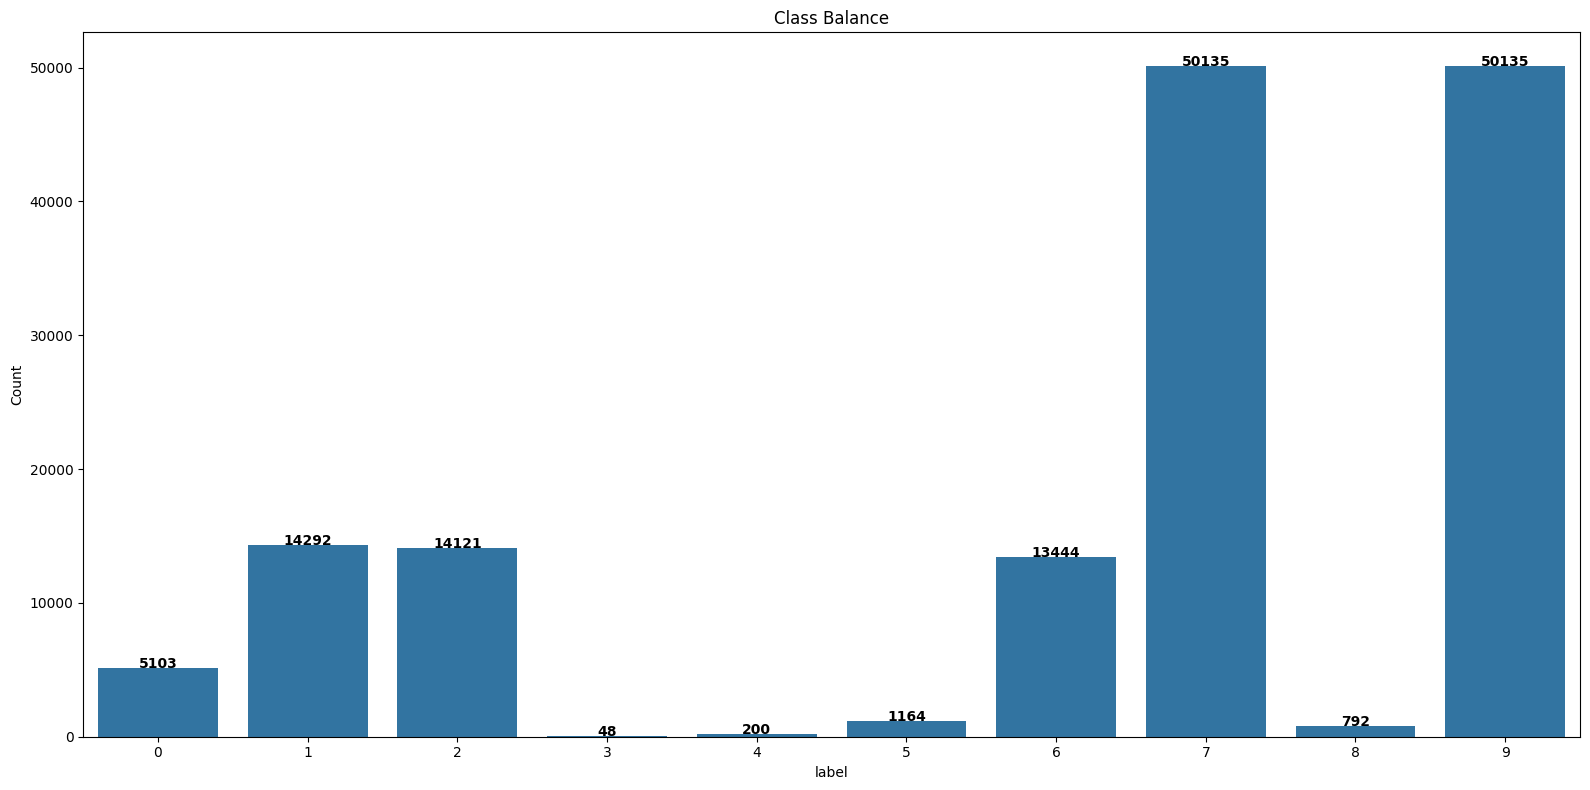

In [ ]:
plot_class_balance()

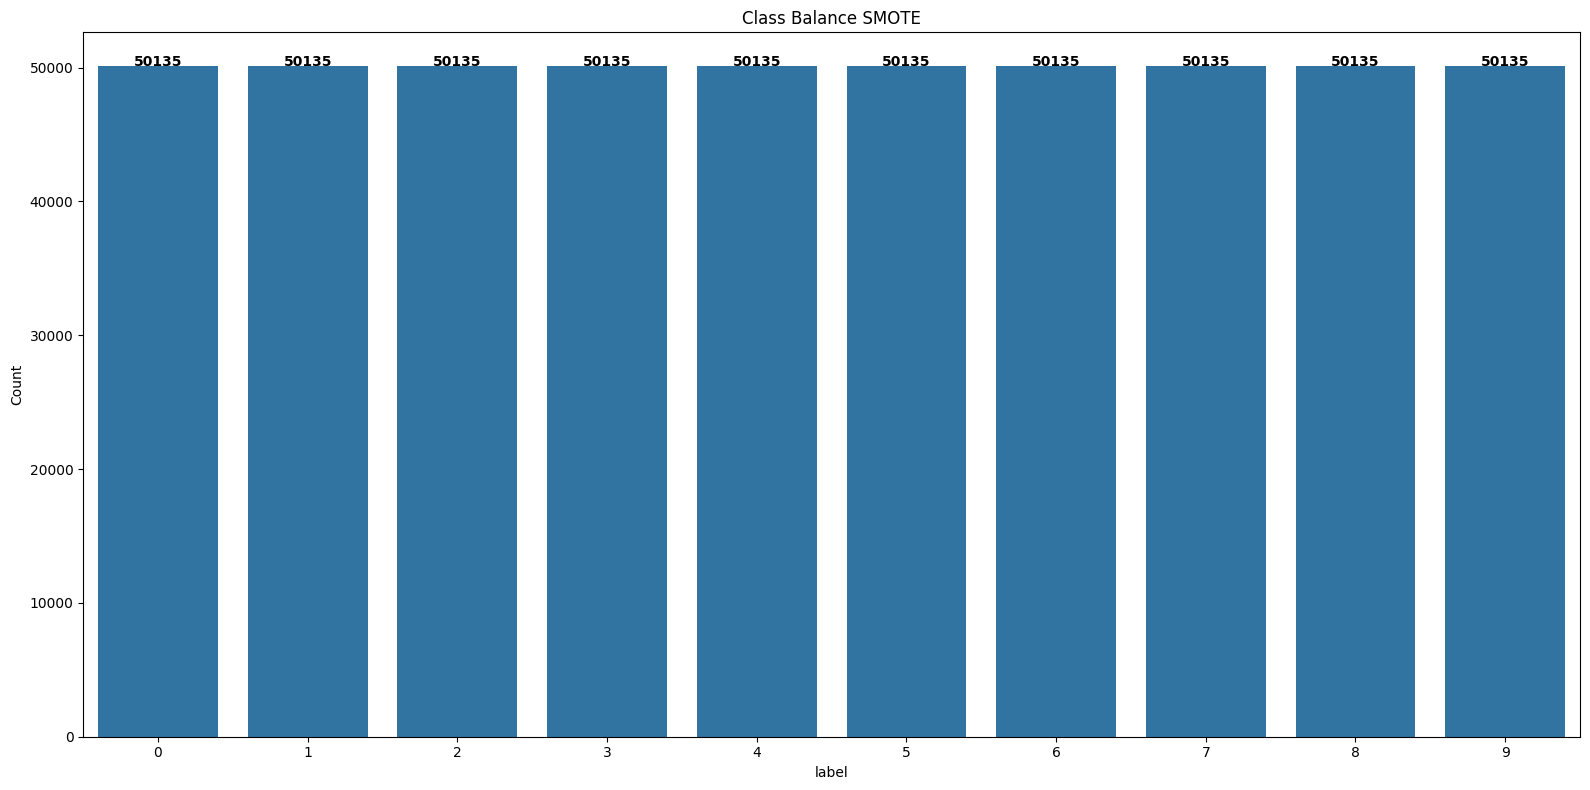

In [ ]:
# Class balancing using SMOTE
smote = SMOTE(
    sampling_strategy='not majority',
    random_state=random_state
)

X_train, y_train = smote.fit_resample(X, y)

plot_class_balance('Class Balance SMOTE', data_frame=pd.DataFrame(y_train, columns=[target_col]))

In [ ]:
# @title Train-test splitting
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    train_size=train_portion,
    random_state=random_state
)

In [ ]:
# @title Using simple DecissionTreeClassifier to determine wether the data has high bias or variance.
# Then this is used to select the proper ensemble technique.

DTC = DecisionTreeClassifier(random_state=random_state)
DTC.fit(X_train, y_train)

train_acc = accuracy_score(y_train, DTC.predict(X_train))
test_acc  = accuracy_score(y_test,  DTC.predict(X_test))
gap = train_acc - test_acc

print(f"Training Accuracy : {train_acc:.4f}")
print(f"Testing Accuracy  : {test_acc:.4f}")
print(f"Gap               : {train_acc - test_acc:.4f}")


# Interpreting the result
if train_acc < 0.75:
    print('High bias, underfitted model. Best to use boosting ie. XGBoost')
elif gap > 0.10:
    print('High variance, overfitted model. Best to use bagging ie. RandomForest')


Training Accuracy : 0.5966
Testing Accuracy  : 0.5703
Gap               : 0.0263
High bias, underfitted model. Best to use boosting ie. XGBoost


## Model Selection, Training and Hyperparameter Tuning
Boosting model such as XGBoost is selected because the dataset has high bias according to the evaluation's result above. Then Bayesian Optimization is used for faster and more efficient hyperparameter finding in the defined search space.

In [ ]:
# @title Define the hyperparameter search space
search_space = {
    'n_estimators'  : Integer(50, 500),
    'learning_rate' : Real(0.01, 0.3, prior='log-uniform'),
    'max_depth'     : Integer(3, 10),
    'subsample'     : Real(0.6, 1.0),
    'colsample_bytree': Real(0.6, 1.0),
}

# Bayesian search
bayes_search = BayesSearchCV(
    estimator=XGBClassifier(        # MODEL SELECTION IS IN HERE <=============
        random_state=random_state,
        eval_metric='mlogloss',
        tree_method='hist',
        device='cuda'
    ),
    search_spaces=search_space,
    n_iter=30,          # number of trials (more = better but slower)
    cv=5,               # cross validation folds
    scoring='accuracy',
    random_state=42,
    n_jobs=1,          # use GPU cores
    verbose=2
)

bayes_search.fit(X_train, y_train)


Fitting 5 folds for each of 1 candidates, totalling 5 fits


/usr/local/lib/python3.12/dist-packages/xgboost/core.py:751: UserWarning: [05:18:19] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


[CV] END colsample_bytree=0.7640415835413256, learning_rate=0.11883357504897696, max_depth=10, n_estimators=192, subsample=0.8680591793075738; total time=   6.6s
[CV] END colsample_bytree=0.7640415835413256, learning_rate=0.11883357504897696, max_depth=10, n_estimators=192, subsample=0.8680591793075738; total time=   5.1s
[CV] END colsample_bytree=0.7640415835413256, learning_rate=0.11883357504897696, max_depth=10, n_estimators=192, subsample=0.8680591793075738; total time=   8.1s
[CV] END colsample_bytree=0.7640415835413256, learning_rate=0.11883357504897696, max_depth=10, n_estimators=192, subsample=0.8680591793075738; total time=   9.4s
[CV] END colsample_bytree=0.7640415835413256, learning_rate=0.11883357504897696, max_depth=10, n_estimators=192, subsample=0.8680591793075738; total time=   6.7s
Fitting 5 folds for each of 1 candidates, totalling 5 fits
[CV] END colsample_bytree=0.9349553422213137, learning_rate=0.2017268796559709, max_depth=5, n_estimators=478, subsample=0.94565116

BayesSearchCV(cv=5,
              estimator=XGBClassifier(base_score=None, booster=None,
                                      callbacks=None, colsample_bylevel=None,
                                      colsample_bynode=None,
                                      colsample_bytree=None, device='cuda',
                                      early_stopping_rounds=None,
                                      enable_categorical=False,
                                      eval_metric='mlogloss',
                                      feature_types=None, feature_weights=None,
                                      gamma=None, grow_policy=None,
                                      importance_type=None,
                                      interaction_constr...
              search_spaces={'colsample_bytree': Real(low=0.6, high=1.0, prior='uniform', transform='normalize'),
                             'learning_rate': Real(low=0.01, high=0.3, prior='log-uniform', transform='normalize'),
                             'max_depth': Integer(low=3, high=10, prior='uniform', transform='normalize'),
                             'n_estimators': Integer(low=50, high=500, prior='uniform', transform='normalize'),
                             'subsample': Real(low=0.6, high=1.0, prior='uniform', transform='normalize')},
              verbose=2)

In [ ]:
# @title Search result
print(f'Best Parameters : {bayes_search.best_params_}')
print(f'Best CV Score   : {bayes_search.best_score_:.4f}')

results = {
    'best_params': dict(bayes_search.best_params_),
    'best_cv_score': float(bayes_search.best_score_)
}

with open(f'{output_dir}/bayes_search_results.json', 'w') as f:
    json.dump(results, f, indent=4)

Best Parameters : OrderedDict({'colsample_bytree': 0.9634207491746941, 'learning_rate': 0.028704298413719777, 'max_depth': 5, 'n_estimators': 77, 'subsample': 0.9004773082375136})
Best CV Score   : 0.5856


In [ ]:
# @title Evaluate on test set
best_model = bayes_search.best_estimator_
y_pred = best_model.predict(X_test)

cf_report = classification_report(
    y_test, y_pred,
    target_names=le.classes_
)

print(cf_report)

with open(f'{output_dir}/classification_report.txt', 'w') as f:
    f.write(cf_report)

              precision    recall  f1-score   support

  Bruteforce       0.99      1.00      0.99      1059
        DDoS       1.00      1.00      1.00      2831
         DoS       1.00      1.00      1.00      2865
        Evil       0.00      0.00      0.00         6
 FakeLanding       1.00      0.06      0.12        31
        MITM       0.68      0.93      0.78       243
      Normal       0.88      0.24      0.38      2593
        Reco       0.41      0.28      0.34     10055
       Reply       0.91      0.43      0.58       149
    Scanning       0.47      0.70      0.56     10055

    accuracy                           0.59     29887
   macro avg       0.73      0.56      0.58     29887
weighted avg       0.61      0.59      0.57     29887



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


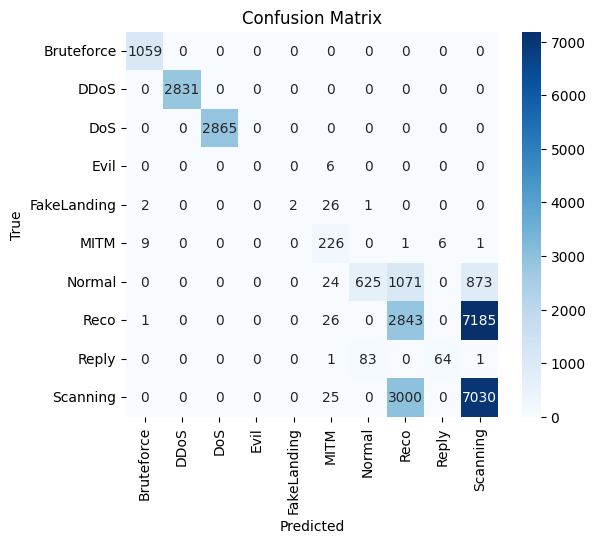

In [ ]:
# @title Confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=np.unique(le.inverse_transform(y_train)),
            yticklabels=np.unique(le.inverse_transform(y_train)))
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.savefig(f'{output_dir}/confsion_matrix.png')
plt.show()

## Stratifed KFold Validation

In [ ]:
# @title Define Stratified K-Fold
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=random_state
)

In [ ]:
# @title Use best params from Bayesian search
best_params = dict(bayes_search.best_params_)
best_params = {k.replace('model__', ''): v for k, v in best_params.items()}

final_model = XGBClassifier(
    **best_params,
    random_state=random_state,
    eval_metric='mlogloss',
    tree_method='hist',
    device='cuda'
)

In [ ]:
# @title Cross Validate
cv_results = cross_validate(
    final_model, X_train, y_train,
    cv=skf,
    scoring='accuracy',
    return_train_score=True,
    n_jobs=1
)

print("Per-fold Results:")
for i, (train, val) in enumerate(zip(cv_results['train_score'], cv_results['test_score'])):
    print(f"  Fold {i+1} → Train: {train:.4f} | Val: {val:.4f}")

print(f"\nMean Train Accuracy : {cv_results['train_score'].mean():.4f} ± {cv_results['train_score'].std():.4f}")
print(f"Mean Val Accuracy   : {cv_results['test_score'].mean():.4f} ± {cv_results['test_score'].std():.4f}")

Per-fold Results:
  Fold 1 → Train: 0.5921 | Val: 0.5853
  Fold 2 → Train: 0.5918 | Val: 0.5841
  Fold 3 → Train: 0.5920 | Val: 0.5845
  Fold 4 → Train: 0.5907 | Val: 0.5886
  Fold 5 → Train: 0.5921 | Val: 0.5852

Mean Train Accuracy : 0.5917 ± 0.0005
Mean Val Accuracy   : 0.5855 ± 0.0016


In [ ]:
# @title Final evaluation on test set
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

cf_report = classification_report(
    y_test, y_pred,
    target_names=le.classes_
)

print(cf_report)

with open(f'{output_dir}/final_classification_report.txt', 'w') as f:
    f.write(cf_report)

              precision    recall  f1-score   support

  Bruteforce       0.99      1.00      0.99      1059
        DDoS       1.00      1.00      1.00      2831
         DoS       1.00      1.00      1.00      2865
        Evil       0.00      0.00      0.00         6
 FakeLanding       1.00      0.06      0.12        31
        MITM       0.68      0.93      0.78       243
      Normal       0.88      0.24      0.38      2593
        Reco       0.41      0.28      0.34     10055
       Reply       0.91      0.43      0.58       149
    Scanning       0.47      0.70      0.56     10055

    accuracy                           0.59     29887
   macro avg       0.73      0.56      0.58     29887
weighted avg       0.61      0.59      0.57     29887



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


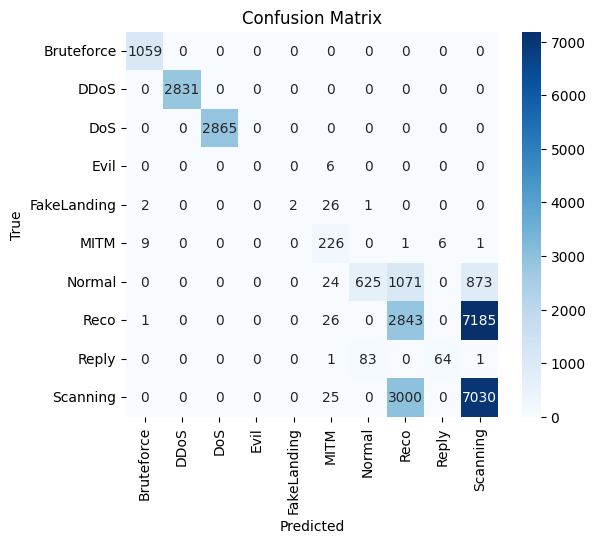

In [ ]:
# @title Final confusion matrix evaluation
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=np.unique(le.inverse_transform(y_train)),
            yticklabels=np.unique(le.inverse_transform(y_train)))
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.savefig(f'{output_dir}/final_confsion_matrix.png')
plt.show()

## Model interpretation using SHAP values

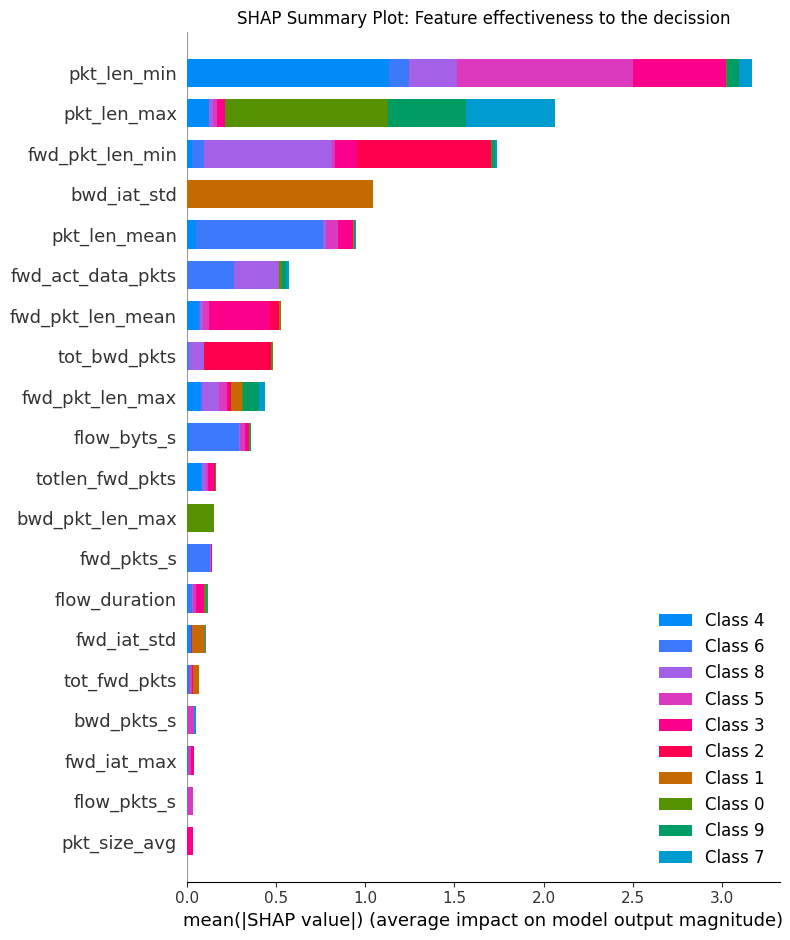

In [ ]:
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 6))
plt.title("SHAP Summary Plot: Feature effectiveness to the decission")
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.savefig(f'{output_dir}/shap_summary.png')
plt.show()

In [ ]:
# @title Save the final model

joblib.dump(final_model, f'{output_dir}/model.joblib')
print(f'Model is saved at {output_dir}')

Model is saved at /content/drive/Shareddrives/AI/experiments/run-1777353481
